# Poster figures

Regenerates the three poster panels **from cached artifacts only** — no model load, no GPU. Each
figure records its source below, so a number on the poster can always be traced back.

| fig | panel | source |
|---|---|---|
| 1 | goal heads | `results/localization/<model>/lam20/head_mask.pt` (via `clock/__head_inspection`) |
| 2 | GoalScope faithfulness + causality | `results/evaluation/goalscope/.../summary.json` (via `fig_n_table_generators/eval_goal`) |
| 3 | boundary intervention | hardcoded from `clock/16_move_on_signal` §1.1 |

Figures 2 and 3 hardcode their numbers — they are small tables and hardcoding keeps this notebook
runnable anywhere. Figure 1 reads the mask directly: a 64x40 grid is too large to paste, and the
mask is the same artifact `__head_inspection` loads, so the two cannot drift.

Everything is sized for print: larger type than a screen figure, and `save_fig` writes **PDF
(vector) + PNG** at `DPI`.

In [1]:
import sys, os, json
sys.path.append("../..")
from pathlib import Path

import numpy as np
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from src.utils import env_utils

RES = env_utils.DEFAULT_RESULTS_DIR
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
SLUG = MODEL_NAME.split("/")[-1]

# ── output ──────────────────────────────────────────────────────────────────
SAVE   = True
DPI    = 400                      # raster DPI; the PDF is vector regardless
OUTDIR = Path("poster_figs")
FMTS   = ("pdf", "png")

def save_fig(fig, name):
    """Write `name.pdf` + `name.png`. PDF is what belongs in the poster (vector = crisp at any
    size); the PNG is for quick preview and for tools that will not place a PDF."""
    if not SAVE:
        print(f"  (SAVE=False, skipped {name})"); return
    OUTDIR.mkdir(parents=True, exist_ok=True)
    for ext in FMTS:
        p = OUTDIR / f"{name}.{ext}"
        fig.savefig(p, dpi=DPI, bbox_inches="tight", facecolor="white", transparent=False)
        print(f"  saved {p}")

# ── shared palette ───────────────────────────────────────────────────────────
# Poster convention: RED marks an INTERVENTION (and the patched generations in the code
# panels); the goal / "what" signal is a matte ochre so it never reads as an intervention.
C_INTERV      = "#bf6a60"   # move-on / boundary intervention
C_INTERV_DARK = "#8c4238"   # second series of the same
C_GOAL        = "#d1a054"   # goal heads (what)
C_NEUTRAL     = "#9a9a9a"   # no intervention / OVERALL

# ── print-oriented defaults ─────────────────────────────────────────────────
# A poster is read at ~1 m; screen defaults (10 pt) vanish. These sizes are what make the
# difference between a figure that reads across a room and one that does not.
mpl.rcParams.update({
    "font.size": 15, "axes.titlesize": 18, "axes.labelsize": 16,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,      # embed real glyphs, not type-3 outlines
})
print(f"model={SLUG}  ->  {OUTDIR}/  (dpi={DPI}, formats={FMTS})")

model=Qwen2.5-Coder-32B-Instruct  ->  poster_figs/  (dpi=400, formats=('pdf', 'png'))


## Figure 1 — goal heads

Config is `__head_inspection`'s default: `tag="lam20"`, `threshold=0.9`, `topk=None`, `band=None`.
`band=None` **with a threshold set** resolves to the model's registered `GOAL_BANDS` entry, which
for this model is layers **25–56** — so this is the same 122-head set the GoalScope evals in
figure 2 use.

grid (64, 40)  band (28, 56)  selected 122 heads
  saved poster_figs/fig1_goal_heads.pdf
  saved poster_figs/fig1_goal_heads.png


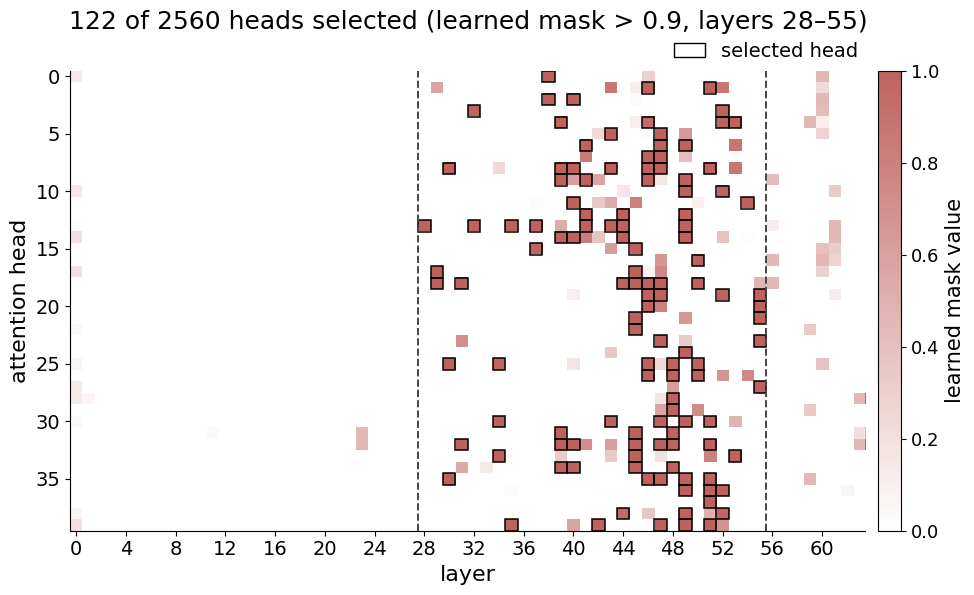

In [13]:
# ── fig 1: goal-head mask ───────────────────────────────────────────────────
from scripts.evaluation.eval_goalscope import default_goal_band

GOAL_CFG = dict(
    tag="lam20", threshold=0.9, topk=None, band=None
)  # band=None + threshold -> GOAL_BANDS

_ck = torch.load(
    os.path.join(RES, "localization", SLUG, GOAL_CFG["tag"], "head_mask.pt"),
    map_location="cpu",
)
_layers = [int(x) for x in _ck["layers"]]
_mv = _ck["mask_values"].numpy()
N_LAYER, N_HEAD = 64, _mv.shape[1]

GRID = np.full((N_LAYER, N_HEAD), np.nan)  # NaN = layer not trained
for i, l in enumerate(_layers):
    GRID[l] = _mv[i]

BAND = tuple(GOAL_CFG["band"] or default_goal_band(MODEL_NAME, n_layer=N_LAYER))
BAND = (28, BAND[1])  # hardcode the start of the band to layer 27 for Qwen2.5-Coder-32B-Instruct
_m = np.nan_to_num(GRID, nan=0.0).copy()
_m[: BAND[0]] = 0
_m[BAND[1] :] = 0
SELECTED = [(int(l), int(h)) for l, h in np.argwhere(_m > GOAL_CFG["threshold"])]
print(f"grid {GRID.shape}  band {BAND}  selected {len(SELECTED)} heads")

fig, ax = plt.subplots(figsize=(10, 6.2))
# ochre, not red: on this poster RED means an intervention, and this panel is localization.
cmap = LinearSegmentedColormap.from_list("goal", ["white", C_GOAL], N=256).copy()
cmap.set_bad("#EFEFEF")
im = ax.imshow(
    np.ma.masked_invalid(GRID.T),
    cmap=cmap,
    aspect="auto",
    vmin=0.0,
    vmax=1.0,
    interpolation="nearest",
)

# grey out everything outside the band, so "selected" reads as a property of the region too
for lo, hi in [(-0.5, BAND[0] - 0.5), (BAND[1] - 0.5, N_LAYER - 0.5)]:
    ax.add_patch(
        patches.Rectangle(
            (lo, -0.5),
            hi - lo,
            N_HEAD,
            facecolor="white",
            alpha=0.55,
            edgecolor="none",
            zorder=2,
        )
    )
for l, h in SELECTED:  # black border = in the selected set
    ax.add_patch(
        patches.Rectangle(
            (l - 0.5, h - 0.5),
            1,
            1,
            linewidth=1.1,
            edgecolor="black",
            facecolor="none",
            zorder=3,
        )
    )
ax.axvline(BAND[0] - 0.5, color="#444", ls="--", lw=1.4, zorder=4)
ax.axvline(BAND[1] - 0.5, color="#444", ls="--", lw=1.4, zorder=4)
ax.set_xticks(range(0, N_LAYER, 4))
ax.set_yticks(range(0, N_HEAD, 5))
ax.set_xlabel("layer")
ax.set_ylabel("attention head")
ax.set_title(
    # f"A sparse set of attention heads carries the next sub-step\n"
    f"{len(SELECTED)} of {N_LAYER * N_HEAD} heads selected "
    f"(learned mask > {GOAL_CFG['threshold']}, layers {BAND[0]}\u2013{BAND[1] - 1})",
    pad=30,
)
cb = fig.colorbar(im, ax=ax, pad=0.015, fraction=0.028)
cb.set_label("learned mask value", fontsize=15)
cb.ax.tick_params(labelsize=13)
ax.legend(
    handles=[patches.Patch(facecolor="none", edgecolor="black", label="selected head")],
    loc="lower right",
    bbox_to_anchor=(1.0, 1.005),
    frameon=False,
    ncol=1,
    handlelength=1.6,
    borderaxespad=0.0,
)
fig.tight_layout()
save_fig(fig, "fig1_goal_heads")
plt.show()

## Figure 2 — GoalScope: faithfulness + causality

`additive`, α=0.2, 122 heads, 512 specs, steering layers 35–46 — the run the poster quotes.

The x-axis is **where in the line the goal-head output is captured**, from before the line exists
through to the first token of the implementation. The leftmost anchors are the claim: the sub-step
is already decodable *before* any of its tokens are written.

* **faithfulness** — a read-out probe describes the sub-step, judged against the implementation the
  model actually went on to write.
* **causality** — the same aggregated output is transplanted into a C++ context; the transfer
  succeeds if the model implements *that* sub-step there.

  saved poster_figs/fig2_goalscope_faithfulness_causality.pdf
  saved poster_figs/fig2_goalscope_faithfulness_causality.png


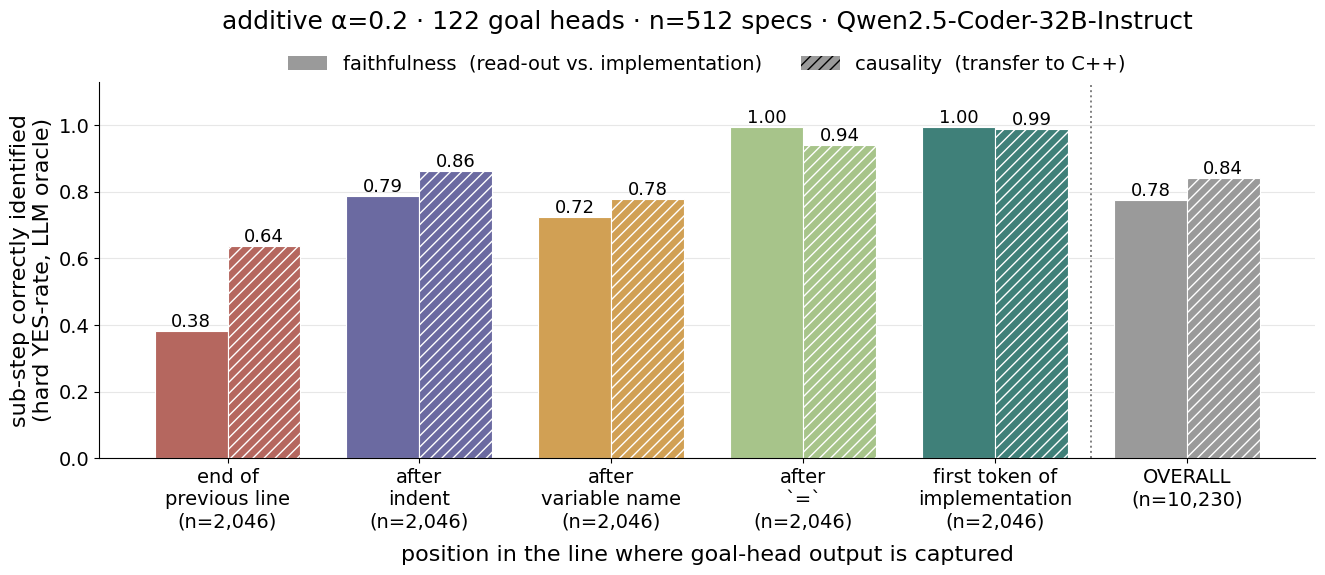

In [11]:
# ── fig 2: faithfulness vs causality by anchor ──────────────────────────────
# Cached from results/evaluation/goalscope/Qwen2.5-Coder-32B-Instruct/{mode}/additive/0.2/
#   heads=goal__layers=35-46__nsteer=all__maxnew=64__span=rule__dtype=int__nspec=512__nc=3-4-5__seed=123
EVAL = {
    "faithfulness": {
        "prev_end": 0.3812,
        "indent": 0.7874,
        "var": 0.7243,
        "eq": 0.9951,
        "first_impl": 0.9956,
        "OVERALL": 0.7767,
    },
    "causality": {
        "prev_end": 0.6369,
        "indent": 0.8612,
        "var": 0.7791,
        "eq": 0.9394,
        "first_impl": 0.9888,
        "OVERALL": 0.8411,
    },
}
N_PER_ANCHOR, N_TOTAL, N_HEADS_EVAL, N_SPECS = 2046, 10230, 122, 512

ANCHORS = ["prev_end", "indent", "var", "eq", "first_impl", "OVERALL"]
ANCHOR_LABEL = {  # descriptive: what position in the line this is
    "prev_end": "end of\nprevious line",
    "indent": "after\nindent",
    "var": "after\nvariable name",
    "eq": "after\n`=`",
    "first_impl": "first token of\nimplementation",
    "OVERALL": "OVERALL",
}
ANCHOR_COLOR = {
    "prev_end": "#b5675f",
    "indent": "#6b6aa1",
    "var": "#d1a054",
    "eq": "#a7c48a",
    "first_impl": "#3f8079",
    "OVERALL": "#9a9a9a",
}

faith = [EVAL["faithfulness"][a] for a in ANCHORS]
causal = [EVAL["causality"][a] for a in ANCHORS]
ns = [N_TOTAL if a == "OVERALL" else N_PER_ANCHOR for a in ANCHORS]
colors = [ANCHOR_COLOR[a] for a in ANCHORS]

x = np.arange(len(ANCHORS))
w = 0.38
fig, ax = plt.subplots(figsize=(13.5, 6.0))
b1 = ax.bar(x - w / 2, faith, w, color=colors, edgecolor="white", linewidth=0.8)
b2 = ax.bar(
    x + w / 2, causal, w, color=colors, edgecolor="white", linewidth=0.8, hatch="///"
)
for bars in (b1, b2):
    for r in bars:
        ax.annotate(
            f"{r.get_height():.2f}",
            (r.get_x() + r.get_width() / 2, r.get_height()),
            ha="center",
            va="bottom",
            fontsize=13,
        )

ax.axvline(len(ANCHORS) - 1.5, color="grey", ls=":", lw=1.4)  # divider before OVERALL
ax.set_xticks(x)
ax.set_xticklabels([f"{ANCHOR_LABEL[a]}\n(n={n:,})" for a, n in zip(ANCHORS, ns)])
ax.set_ylim(0, 1.13)
ax.set_ylabel("sub-step correctly identified\n(hard YES-rate, LLM oracle)")
ax.set_xlabel("position in the line where goal-head output is captured", labelpad=10)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.set_title(
    # "Steering with goal-head output verbalizes the sub-step and transfers it to C++\n"
    f"additive \u03b1=0.2 \u00b7 {N_HEADS_EVAL} goal heads \u00b7 "
    f"n={N_SPECS} specs \u00b7 {SLUG}",
    pad=38,
)
ax.legend(
    handles=[
        Patch(facecolor="#9a9a9a", label="faithfulness  (read-out vs. implementation)"),
        Patch(facecolor="#9a9a9a", hatch="///", label="causality  (transfer to C++)"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=2,
    frameon=False,
    borderaxespad=0.0,
    columnspacing=2.0,
    handlelength=2.0,
)
fig.tight_layout()
save_fig(fig, "fig2_goalscope_faithfulness_causality")
plt.show()

## Figure 3 — boundary intervention

From `clock/16_move_on_signal` §1.1: **one** move-on vector, cached from `a,b,c`-named prompts,
patched into three different variable-naming schemes. α=2.0, N=128 per scheme.

Only the **patched** arm is shown — the clean bars are dropped per the poster edit. `SHOW_CLEAN_REF`
puts the clean rate back as a single dashed reference line if you want the baseline without the
paired-bar clutter; note that with it off, the figure has no visible control, so the caption or the
adjacent text has to supply one.

  saved poster_figs/fig3_boundary_move_on.pdf
  saved poster_figs/fig3_boundary_move_on.png


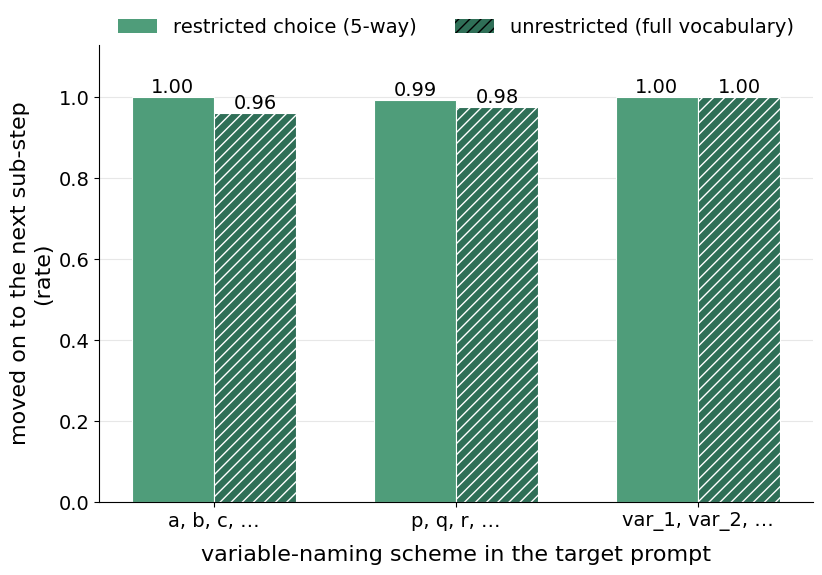

In [14]:
# ── fig 3: move-on transfer across naming schemes ───────────────────────────
# Hardcoded from clock/16_move_on_signal §1.1 (decision arm; alpha=2.0, N=128 per scheme).
MOVEON = {  # scheme: (restricted k-way, full vocab), clean = (kway, vocab)
    "letters_a": dict(patched=(1.000, 0.961), clean=(0.094, 0.047)),
    "letters_p": dict(patched=(0.992, 0.977), clean=(0.070, 0.055)),
    "indexed": dict(patched=(1.000, 1.000), clean=(0.070, 0.070)),
}
SCHEME_LABEL = {
    "letters_a": "a, b, c, \u2026",
    "letters_p": "p, q, r, \u2026",
    "indexed": "var_1, var_2, \u2026",
}
N_PER_SCHEME, ALPHA_MOVEON = 128, 2.0
SHOW_CLEAN_REF = False  # True -> dashed line at the mean clean rate

schemes = list(MOVEON)
restricted = [MOVEON[s]["patched"][0] for s in schemes]
fullvocab = [MOVEON[s]["patched"][1] for s in schemes]

x = np.arange(len(schemes))
w = 0.34
fig, ax = plt.subplots(figsize=(8.6, 6.0))
b1 = ax.bar(x - w / 2, restricted, w, color=C_INTERV, edgecolor="white", linewidth=0.8)
b2 = ax.bar(
    x + w / 2,
    fullvocab,
    w,
    color=C_INTERV_DARK,
    edgecolor="white",
    linewidth=0.8,
    hatch="///",
)
for bars in (b1, b2):
    for r in bars:
        ax.annotate(
            f"{r.get_height():.2f}",
            (r.get_x() + r.get_width() / 2, r.get_height()),
            ha="center",
            va="bottom",
            fontsize=14,
        )

if SHOW_CLEAN_REF:
    ref = float(np.mean([MOVEON[s]["clean"][1] for s in schemes]))
    ax.axhline(ref, color="#777", ls="--", lw=1.6, zorder=1)
    ax.annotate(
        f"no intervention ({ref:.2f})",
        (len(schemes) - 0.5, ref + 0.02),
        ha="right",
        va="bottom",
        fontsize=13,
        color="#555",
    )

ax.set_xticks(x)
ax.set_xticklabels([SCHEME_LABEL[s] for s in schemes])
ax.set_ylim(0, 1.13)
ax.set_ylabel("moved on to the next sub-step\n(rate)")
ax.set_xlabel("variable-naming scheme in the target prompt", labelpad=10)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
# ax.set_title(
#     "One boundary vector makes the LM move on, whatever the variables are called\n"
#     f"cached from `a,b,c` prompts \u00b7 \u03b1={ALPHA_MOVEON} \u00b7 "
#     f"n={N_PER_SCHEME} per scheme \u00b7 {SLUG}",
#     pad=38,
# )
ax.legend(
    handles=[
        Patch(facecolor=C_INTERV, label="restricted choice (5-way)"),
        Patch(facecolor=C_INTERV_DARK, hatch="///", label="unrestricted (full vocabulary)"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=2,
    frameon=False,
    borderaxespad=0.0,
    columnspacing=2.0,
    handlelength=2.0,
)
fig.tight_layout()
save_fig(fig, "fig3_boundary_move_on")
plt.show()

## Figure 4 — dissociation (fills the bottom-right gap)

From `clock/11_goal_vs_impulse` §4. **Same** injection site (pivot, `PATCH_POS=-2`), same α=2.0,
same N=256 prompts — only the head set differs. Goal-head output barely advances the program;
decision-head output almost always does.

This is the panel that earns "Distinct Mechanisms" in the title: without it a reader can still
read the poster as one signal perturbed two ways. Sized for the empty bottom-right block.

In [ ]:
# ── fig 4: goal heads vs decision heads, same intervention ──────────────────
# Hardcoded from clock/11_goal_vs_impulse §4 ("move-on at the pivot", alpha=2.0, N=256, pivot=-2).
# NOTE the naming: these heads are called "decision" heads in the source notebooks, the trained
# masks (results/.../completion_mask/) and scripts.clock.train_completion_mask. "boundary" is the
# poster-facing name only — keep the code-side name when tracing a number back.
DISSOC = {                       # arm: (move-on argmax rate, colour)
    "no intervention":       (0.047, C_NEUTRAL),
    "goal heads\n(what)":     (0.152, C_GOAL),
    "boundary heads\n(when)": (0.977, C_INTERV),
}
N_DISSOC, ALPHA_DISSOC = 256, 2.0

names = list(DISSOC)
vals  = [DISSOC[k][0] for k in names]
cols  = [DISSOC[k][1] for k in names]

fig, ax = plt.subplots(figsize=(7.4, 5.6))
bars = ax.bar(np.arange(len(names)), vals, 0.6, color=cols, edgecolor="white", linewidth=0.8)
for r in bars:
    ax.annotate(f"{r.get_height():.2f}", (r.get_x() + r.get_width() / 2, r.get_height()),
                ha="center", va="bottom", fontsize=16)

ax.set_xticks(np.arange(len(names))); ax.set_xticklabels(names)
ax.set_ylim(0, 1.13)
ax.set_ylabel("moved on to the next sub-step\n(rate)")
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
ax.set_title("The two signals are separable\n"
             "identical patch site and strength \u2014 only the head set differs\n"
             f"\u03b1={ALPHA_DISSOC} \u00b7 n={N_DISSOC} \u00b7 {SLUG}", pad=16)
fig.tight_layout()
save_fig(fig, "fig4_goal_vs_decision")
plt.show()